# DATA 621 - Homework 02: Classification Metrics

## Project objective

This project evaluates an already scored binary classifier using the supplied actual labels, predicted labels, and predicted probabilities. The goal is to calculate and interpret threshold-based classification metrics and probability-based ROC/AUC, then verify the calculations with `scikit-learn`. Model training is outside the scope of this assignment because the provided data already contains the model's outputs. Class `1` is treated as the positive class throughout.


## Data Loading, Inspection and Confusion Matrix

### Data Loading and Inspection
To complete this assignment, the dataset was first uploaded to the group GitHub repository and then loaded directly from the raw GitHub URL using `pandas`. By using `pandas.read_csv()` with the raw GitHub URL, it ensures the notebook is 100% reproducible without requiring local file downloads.   

In [1]:
import pandas as pd
import numpy as np

# Load the dataset directly from the raw GitHub URL
url = "https://raw.githubusercontent.com/alinsimon/data621-data-mining/refs/heads/main/homeworks/hw02/data/classification-output-data.csv"
df = pd.read_csv(url)

# Verify dataset dimensions (181 observations, 11 columns)
print(f"Dataset shape: {df.shape}")

# Inspect the first 5 rows of the three key columns
key_cols = ['class', 'scored.class', 'scored.probability']
print(df[key_cols].head())

Dataset shape: (181, 11)
   class  scored.class  scored.probability
0      0             0            0.328452
1      0             0            0.273190
2      1             0            0.109660
3      0             0            0.055998
4      0             0            0.100491


### Confusion Matrix
The cleanest way to generate a labeled raw confusion matrix is by using `pd.crosstab()` because the order in which the arguments are passed explicitly defines what the rows and columns represent.

In [2]:
def get_confusion_matrix(data, actual_col='class', predicted_col='scored.class'):
    """
    Returns the raw confusion matrix using pandas crosstab.
    Rows (index) = Actual Class
    Columns = Predicted Class
    """
    return pd.crosstab(
        index=data[actual_col],
        columns=data[predicted_col],
        rownames=['Actual (class)'],
        colnames=['Predicted (scored.class)'],
        margins=True  # Adds row/column totals for easy verification
    )

conf_matrix = get_confusion_matrix(df)
print(conf_matrix)

Predicted (scored.class)    0   1  All
Actual (class)                        
0                         119   5  124
1                          30  27   57
All                       149  32  181


#### Confusion Matrix Explained

In the primary `pd.crosstab(df['class'], df['scored.class']` output, the rows represent the actual class (`class`), while the columns represent the predicted class (`scored.class`) at the 0.5 probability threshold. 
Row `0` contains all 124 observations that are actually negative (`class == 0`) and Row `1` contains all 57 observations that are actually positive (`class == 1`).
Column `0` contains all 149 observations predicted to be negative (`scored.class == 0`), and Column `1` contains all 32 observations predicted to be positive (`scored.class == 1`).

*Breakdown of Quadrants (N = 181)*

| Metric | Cell Coordinate (Actual, Predicted) | Count | Percentage | Meaning |
|:---|:---|---:|---:|:---|
| **True Negatives ($TN$)** | `(0, 0)` — Top-Left | **119** | 65.75% | The actual class was `0` and the model correctly predicted `0`. |
| **False Positives ($FP$)** | `(0, 1)` — Top-Right | **5** | 2.76% | The actual class was `0`, but the model incorrectly predicted `1` (Type I Error). |
| **False Negatives ($FN$)** | `(1, 0)` — Bottom-Left | **30** | 16.57% | The actual class was `1`, but the model incorrectly predicted `0` (Type II Error). |
| **True Positives ($TP$)** | `(1, 1)` — Bottom-Right | **27** | 14.92% | The actual class was `1` and the model correctly predicted `1`. |

Out of 181 total observations, the model classified $119 + 27 = 146$ correctly ($80.66\%$ accuracy) and misclassified $5 + 30 = 35$ observations ($19.34\%$ error rate).The errors are heavily skewed toward False Negatives (30) compared to False Positives (5), meaning the model is conservative at the 0.5 threshold—when it predicts a positive case (1), it is usually right, but it misses more than half of the actual positive cases ($27 / 57 \approx 47.37\%$ sensitivity).

## Implement and Interpret the Classification Metrics

Following Kuhn & Johnson, *Applied Predictive Modeling* (Chapter 11), each metric is implemented from the confusion-matrix counts with class `1` as the positive (event) class. Each function takes the data frame and returns a single value, then is checked against `scikit-learn`.

In [8]:
def _counts(data, actual_col='class', predicted_col='scored.class'):
    a, p = data[actual_col], data[predicted_col]
    tp = int(((a == 1) & (p == 1)).sum())
    tn = int(((a == 0) & (p == 0)).sum())
    fp = int(((a == 0) & (p == 1)).sum())
    fn = int(((a == 1) & (p == 0)).sum())
    return tp, tn, fp, fn

def accuracy(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return (tp + tn) / (tp + tn + fp + fn)

def classification_error_rate(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return (fp + fn) / (tp + tn + fp + fn)

def precision(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tp / (tp + fp)

def sensitivity(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tp / (tp + fn)

def specificity(data, actual_col='class', predicted_col='scored.class'):
    tp, tn, fp, fn = _counts(data, actual_col, predicted_col)
    return tn / (tn + fp)

def f1_score_manual(data, actual_col='class', predicted_col='scored.class'):
    p = precision(data, actual_col, predicted_col)
    s = sensitivity(data, actual_col, predicted_col)
    return 2 * p * s / (p + s)

metrics = pd.Series({
    'Accuracy': accuracy(df),
    'Classification error rate': classification_error_rate(df),
    'Precision': precision(df),
    'Sensitivity (recall)': sensitivity(df),
    'Specificity': specificity(df),
    'F1 score': f1_score_manual(df),
}, name='Value')
print(metrics.round(4))
print('Accuracy + error rate =', accuracy(df) + classification_error_rate(df))

Accuracy                     0.8066
Classification error rate    0.1934
Precision                    0.8438
Sensitivity (recall)         0.4737
Specificity                  0.9597
F1 score                     0.6067
Name: Value, dtype: float64
Accuracy + error rate = 1.0


### F1 score bounds

$F_1 = \dfrac{2 \cdot \text{precision} \cdot \text{sensitivity}}{\text{precision} + \text{sensitivity}}$. Both precision and sensitivity lie in $[0, 1]$. If either is $0$ then $F_1 = 0$, and if both are $1$ then $F_1 = 1$. Because $F_1$ is the harmonic mean of the two, it never exceeds the larger of them, so $0 \le F_1 \le 1$. It reaches $0$ only when there are no true positives, and $1$ only when there are no false positives and no false negatives. The code below checks this over a grid of precision and sensitivity values.

#### Proof that $0\le F_1 \le 1$

1. **Domain of Precision ($P$) and Sensitivity ($S$):**  
   Since True Positives ($TP$), False Positives ($FP$), and False Negatives ($FN$) are non-negative ($TP, FP, FN \ge 0$), both metrics are proportions bounded on $[0, 1]$:
   $$0 \le P \le 1 \quad \text{and} \quad 0 \le S \le 1$$

2. **Lower Bound ($F_1 \ge 0$):**
 Since $P\ge 0$ and $S\ge 0$, the numerator $2\cdot P\cdot S\ge 0$ and denominator $P + S\ge 0$. If either $P=0$ or $S=0$,  $F_1=0$.

3. **Upper Bound ($F_1\le 1$):**
  By the **Arithmetic Mean - Harmonic Mean (AM-HM) Inequality**:
  $$\text{Harmonic Mean}\le\text{Arithmetic Mean}$$
  $$\frac{2\cdot P\cdot S}{P + S}\le\frac{P+S}{2}$$

  Since $P\le 1$ and $S\le 1$, their average satisfies $\frac{P+S}{2}\le 1$.
  Therefore:
  $$F_1 = \frac{2\cdot P\cdot S}{P+S}\le\frac{P+S}{2}\le 1$$

The code below checks this over a grid of precision and sensitivity values.

In [9]:
grid = np.linspace(0.001, 1, 200)
P, S = np.meshgrid(grid, grid)
F = 2 * P * S / (P + S)
print(f"min F1 over grid = {F.min():.4f}, max F1 over grid = {F.max():.4f}")

min F1 over grid = 0.0010, max F1 over grid = 1.0000


### ROC Curve and AUC

The ROC curve plots sensitivity (true positive rate) against $1 -$ specificity (false positive rate) as the classification threshold moves from 0 to 1 over `scored.probability`. The AUC is computed with the trapezoidal rule.

AUC (manual, trapezoidal) = 0.8503


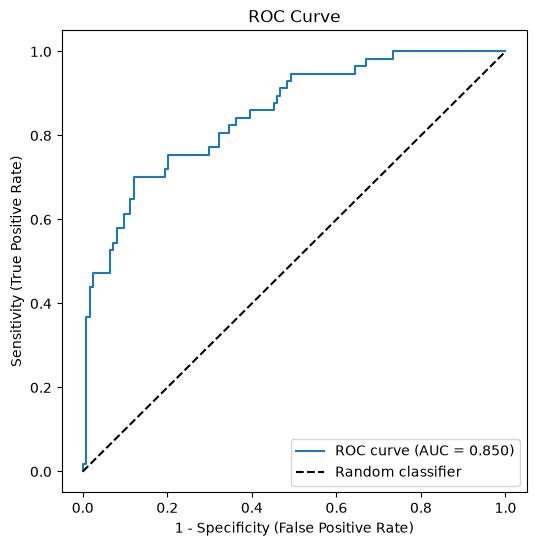

In [10]:
import matplotlib.pyplot as plt

def roc_curve_manual(data, actual_col='class', prob_col='scored.probability'):
    actual = data[actual_col].to_numpy()
    prob = data[prob_col].to_numpy()
    thresholds = np.append(np.sort(np.unique(prob))[::-1], -np.inf)
    thresholds = np.insert(thresholds, 0, np.inf)
    pos, neg = (actual == 1).sum(), (actual == 0).sum()
    tpr, fpr = [], []
    for t in thresholds:
        pred = prob >= t
        tpr.append(((pred) & (actual == 1)).sum() / pos)
        fpr.append(((pred) & (actual == 0)).sum() / neg)
    fpr, tpr = np.array(fpr), np.array(tpr)
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    return fpr, tpr, auc

fpr, tpr, auc_manual = roc_curve_manual(df)
print(f"AUC (manual, trapezoidal) = {auc_manual:.4f}")

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_manual:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('1 - Specificity (False Positive Rate)')
plt.ylabel('Sensitivity (True Positive Rate)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

## Verification with scikit-learn

In [11]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

y, yhat, prob = df['class'], df['scored.class'], df['scored.probability']
tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
print('sklearn confusion matrix (TN, FP, FN, TP):', (tn, fp, fn, tp))

comparison = pd.DataFrame({
    'Manual': [accuracy(df), precision(df), sensitivity(df), specificity(df),
               f1_score_manual(df), auc_manual],
    'scikit-learn': [accuracy_score(y, yhat), precision_score(y, yhat),
                     recall_score(y, yhat), tn / (tn + fp),
                     f1_score(y, yhat), roc_auc_score(y, prob)],
}, index=['Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1 score', 'AUC'])
comparison['Match'] = np.isclose(comparison['Manual'], comparison['scikit-learn'])
print(comparison.round(4))

sklearn confusion matrix (TN, FP, FN, TP): (np.int64(119), np.int64(5), np.int64(30), np.int64(27))
             Manual  scikit-learn  Match
Accuracy     0.8066        0.8066   True
Precision    0.8438        0.8438   True
Sensitivity  0.4737        0.4737   True
Specificity  0.9597        0.9597   True
F1 score     0.6067        0.6067   True
AUC          0.8503        0.8503   True


### Interpretation

| Metric | Value | Interpretation |
|:---|---:|:---|
| Accuracy | 0.8066 | About 81% of all cases are classified correctly. |
| Error rate | 0.1934 | About 19% are misclassified; accuracy + error rate = 1. |
| Precision | 0.8438 | When the model predicts positive, it is right about 84% of the time. |
| Sensitivity | 0.4737 | The model finds fewer than half of the actual positives. |
| Specificity | 0.9597 | It correctly identifies about 96% of the actual negatives. |
| F1 score | 0.6067 | The harmonic mean is pulled down by the low sensitivity. |
| AUC | 0.8503 | A randomly chosen positive gets a higher score than a randomly chosen negative about 85% of the time. |

The classifier is conservative at the 0.5 threshold: high precision and specificity, but low sensitivity (30 false negatives vs. 5 false positives). Accuracy alone is flattering because 124 of 181 cases are negative (68.5%), so always predicting `0` would already be 68.5% accurate. The AUC of 0.85 shows the probabilities separate the classes well, so sensitivity could be raised by lowering the threshold, at the cost of more false positives. If missing a positive is costly, a lower threshold chosen from the ROC curve is worth considering. The manual calculations match `scikit-learn` for every metric.